<img src="https://i0.wp.com/bitcoinke.io/wp-content/uploads/2021/04/Forbest-Billionaire-List-2021.jpg?resize=1155%2C675&ssl=1" width="400">

# 🤑💵💰 Billionaires Analysis

In this notebook, we explore the Forbes 2021 billionaire dataset using `Pandas` and `Matplotlib`. 

Dataset [Forbes Billionaires of 2021 on Kaggle](https://www.kaggle.com/datasets/roysouravcu/forbes-billionaires-of-2021).

### Topics
- Inspect the dataset and identify missing values
- Clean the missing values in `Age` and `NetWorth` columns
- Convert net worth into a numeric column
- Look for patterns across wealth, sources, industries, and countries
- Rank billionaires by net worth
- Compare the most common sources of wealth
- Compare industries and countries with the most billionaires
- Create bar charts and pie charts to communicate findings

**Question for the lesson:** Which countries, industries, and sources of wealth are most common among the billionaires?

> **Estimated time: 30 min**

## 1 · Import the tools

These three libraries cover the main workflow: tables, numerical operations, and visualizations.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


%matplotlib inline

## 2 · Load and inspect the table

The CSV file should be in the same folder as this notebook. Start with a small preview before analyzing the data.

In [2]:
data_frame = pd.read_csv("Billionaire.csv")
data_frame.head()

,Name,NetWorth,Country,Source,Rank,Age,Industry
0,Jeff Bezos,$177 B,United States,Amazon,1,57.0,Technology
1,Elon Musk,$151 B,United States,"Tesla, SpaceX",2,49.0,Automotive
2,Bernard Arnault & family,$150 B,France,LVMH,3,72.0,Fashion & Retail
3,Bill Gates,$124 B,United States,Microsoft,4,65.0,Technology
4,Mark Zuckerberg,$97 B,United States,Facebook,5,36.0,Technology


## 3 · Check for missing values

Before we go ahead, let’s see whether or not this dataset contains missing values:

In [3]:
data_frame.isnull().sum()

Name         0
NetWorth     0
Country      0
Source       0
Rank         0
Age         79
Industry     0
dtype: int64

Remove incomplete rows

In [4]:
data_frame = data_frame.dropna()

## 3 · Clean the net worth column

The NetWorth column in this dataset has a $ sign at the beginning of Billionaires’ Net worth and B at the end. 

So we need to remove these signs and convert the NetWorth column to float:

In [5]:
data_frame["NetWorth"] = data_frame["NetWorth"].str.strip("$")
data_frame["NetWorth"] = data_frame["NetWorth"].str.strip("B")
data_frame["NetWorth"] = data_frame["NetWorth"].astype(float)

In [6]:
data_frame.head()

,Name,NetWorth,Country,Source,Rank,Age,Industry
0,Jeff Bezos,177.0,United States,Amazon,1,57.0,Technology
1,Elon Musk,151.0,United States,"Tesla, SpaceX",2,49.0,Automotive
2,Bernard Arnault & family,150.0,France,LVMH,3,72.0,Fashion & Retail
3,Bill Gates,124.0,United States,Microsoft,4,65.0,Technology
4,Mark Zuckerberg,97.0,United States,Facebook,5,36.0,Technology


## 4 · Rank billionaires by net worth

Now let’s have a look at the top 20 billionaires according to their NetWorth:

In [7]:
df = data_frame.sort_values(by = ["NetWorth"], ascending=False).head(20)
df

,Name,NetWorth,Country,Source,Rank,Age,Industry
0,Jeff Bezos,177.0,United States,Amazon,1,57.0,Technology
1,Elon Musk,151.0,United States,"Tesla, SpaceX",2,49.0,Automotive
2,Bernard Arnault & family,150.0,France,LVMH,3,72.0,Fashion & Retail
3,Bill Gates,124.0,United States,Microsoft,4,65.0,Technology
4,Mark Zuckerberg,97.0,United States,Facebook,5,36.0,Technology
5,Warren Buffett,96.0,United States,Berkshire Hathaway,6,90.0,Finance & Investments
6,Larry Ellison,93.0,United States,software,7,76.0,Technology
7,Larry Page,91.5,United States,Google,8,48.0,Technology
8,Sergey Brin,89.0,United States,Google,9,47.0,Technology
9,Mukesh Ambani,84.5,India,diversified,10,63.0,Diversified


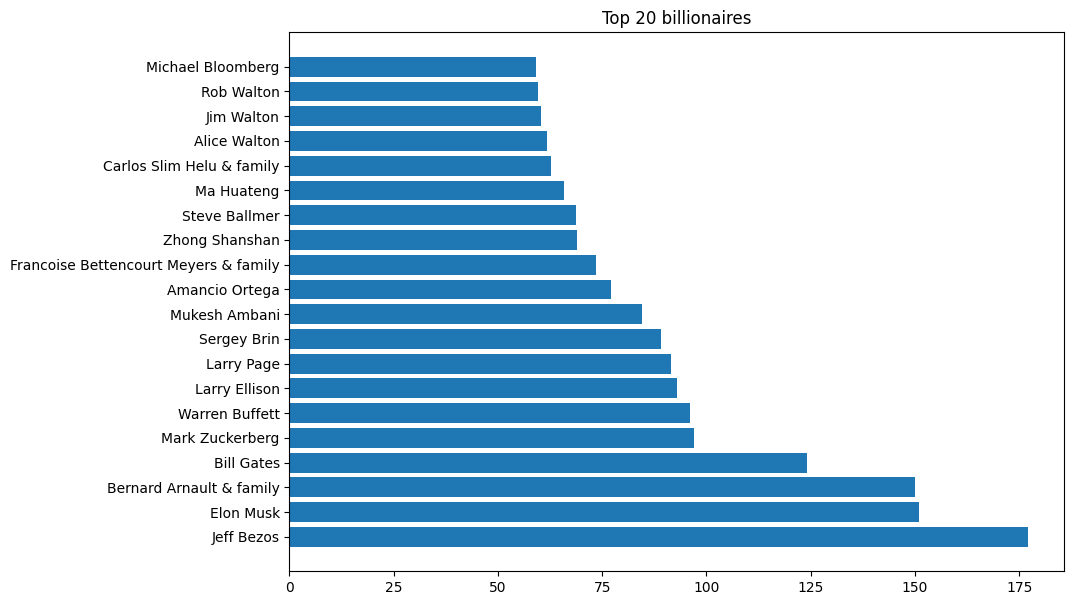

In [8]:
plt.figure(figsize=(10, 7))
plt.barh(df["Name"], df["NetWorth"])
plt.title("Top 20 billionaires")
plt.show()

## 5 · Compare sources of wealth

Now let’s have a look at the top 5 domains with the most number of billionaires:

In [9]:
df = data_frame["Source"].value_counts().head().reset_index()
df

,Source,count
0,real estate,169
1,pharmaceuticals,96
2,investments,89
3,diversified,78
4,software,61


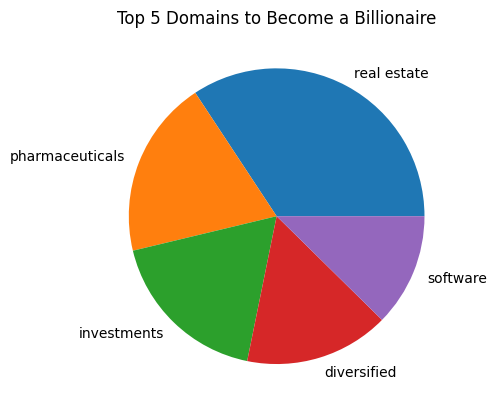

In [10]:
plt.pie(df["count"], labels=df["Source"])
plt.title("Top 5 Domains to Become a Billionaire")
plt.show()

## 6 · Compare industries

Now let’s have a look at the top 10 industries with the most number of billionaires:

In [11]:
df = data_frame['Industry'].value_counts().reset_index()
df

,Industry,count
0,Finance & Investments,365
1,Technology,355
2,Manufacturing,317
3,Fashion & Retail,268
4,Healthcare,213
5,Real Estate,211
6,Food & Beverage,204
7,Diversified,180
8,Energy,99
9,Media & Entertainment,92


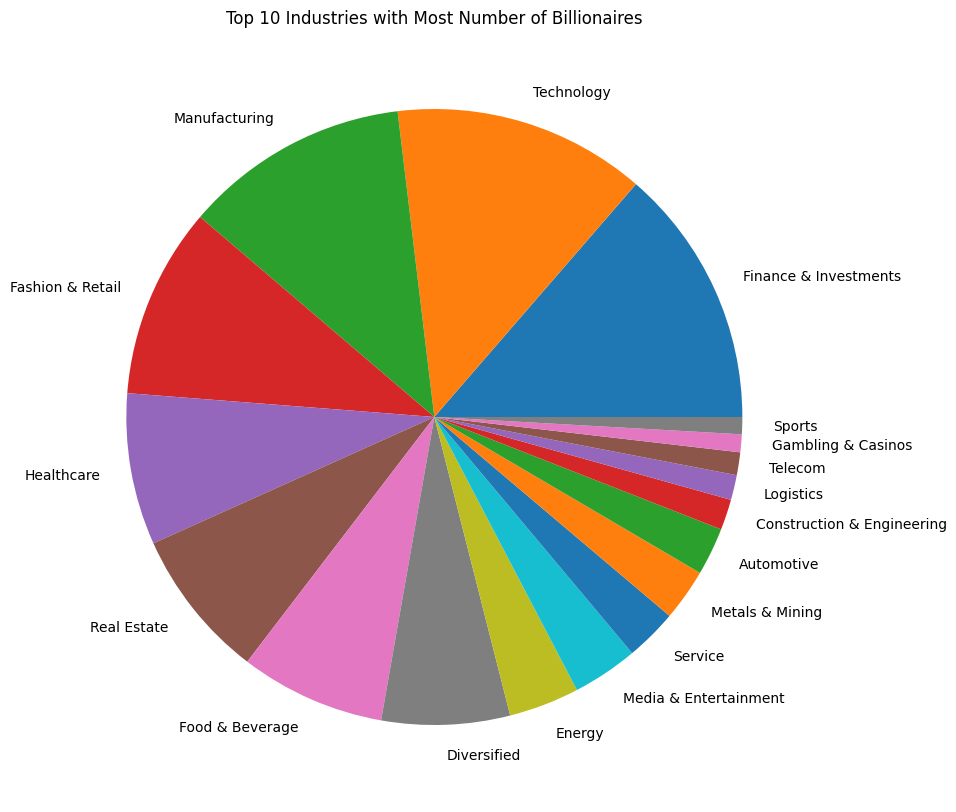

In [12]:
plt.figure(figsize=(24, 10))
plt.pie(df["count"], labels=df["Industry"])
plt.title("Top 10 Industries with Most Number of Billionaires")
plt.show()

## 7 · Compare countries

Now let’s have a look at the top 5 countries with the most number of billionaires:

In [13]:
df = data_frame["Country"].value_counts().head().reset_index()
df

,Country,count
0,United States,720
1,China,610
2,India,134
3,Russia,118
4,Germany,115


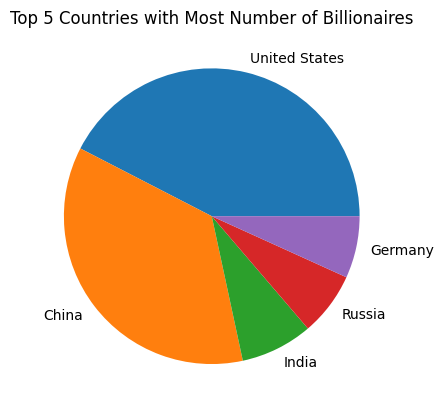

In [14]:
plt.pie(df["count"], labels=df["Country"])
plt.title("Top 5 Countries with Most Number of Billionaires")
plt.show()

### 🇺🇸🇨🇳

The visualization above shows that the United States and China are the countries from which most people become billionaires. 

So that means the business environment and the startup success rate is really good in the US and China compared to the rest of the world.

***

assignment -- Aryan Hashemi

***

In [15]:
# شمارش صنعت‌ها از فایل اصلی
industry_data = pd.read_csv("Billionaire.csv")

industry_counts = industry_data["Industry"].value_counts()

# نگه داشتن 10 صنعت اول و جمع کردن بقیه در Other
top_10_industries = industry_counts.head(10)
other_count = industry_counts.iloc[10:].sum()

industry_counts_final = pd.concat([
    top_10_industries,
    pd.Series({"Other": other_count})
])

industry_result = industry_counts_final.reset_index()
industry_result.columns = ["Industry", "count"]

industry_result

,Industry,count
0,Finance & Investments,371
1,Technology,365
2,Manufacturing,331
3,Fashion & Retail,273
4,Healthcare,221
5,Food & Beverage,219
6,Real Estate,215
7,Diversified,188
8,Energy,100
9,Media & Entertainment,95


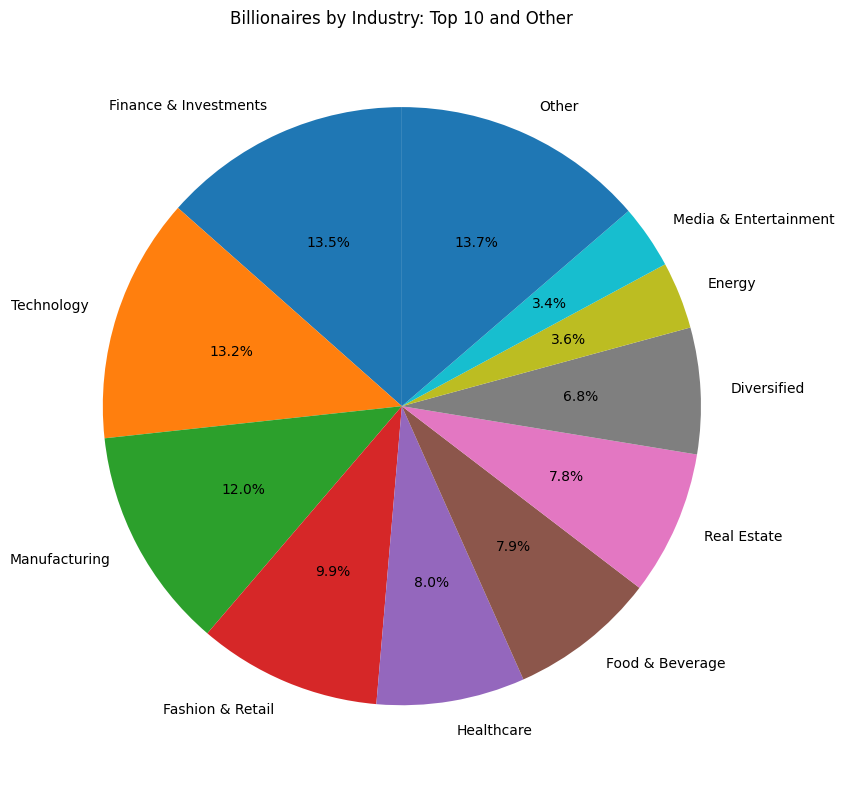

In [16]:
plt.figure(figsize=(10, 8))
plt.pie(
    industry_result["count"],
    labels=industry_result["Industry"],
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Billionaires by Industry: Top 10 and Other")
plt.tight_layout()
plt.show()